# Data Loading dan Preparation


In [24]:
# Memuat library yang dibutuhkan dalam pemrosesan data dan pembuatan
# model dengan menggunakan SVM dan ANN. Pertimbangan data dari Kaggle
import torch
import torch.nn as nn
import torch.nn.functional as func
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

import os
from torch.utils.data import DataLoader
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report

In [25]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cpu


In [26]:
dataset = pd.read_csv("./data/heart.csv")
print(dataset.head())

   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA        140          289          0     Normal    172   
1   49   F           NAP        160          180          0     Normal    156   
2   37   M           ATA        130          283          0         ST     98   
3   48   F           ASY        138          214          0     Normal    108   
4   54   M           NAP        150          195          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat             1  
4              N      0.0       Up             0  


In [27]:
dataset.dtypes

Age                 int64
Sex                   str
ChestPainType         str
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG            str
MaxHR               int64
ExerciseAngina        str
Oldpeak           float64
ST_Slope              str
HeartDisease        int64
dtype: object

In [28]:
# 1. Ganti angka 0 menjadi NaN (Null) HANYA untuk kolom yang tidak logis jika bernilai 0
# (Age, Sex, FastingBS, RestingECG, ExerciseAngina, ST_Slope, HeartDisease biarkan saja, karena 0 di sana masuk akal)
kolom_untuk_diperbaiki = ['RestingBP', 'Cholesterol', 'MaxHR']

for kolom in kolom_untuk_diperbaiki:
    dataset[kolom] = dataset[kolom].replace(0, np.nan)

# 2. Isi NaN dengan nilai rata-rata (Mean) dari kolom tersebut (Imputasi)
dataset['RestingBP'] = dataset['RestingBP'].fillna(dataset['RestingBP'].mean())
dataset['Cholesterol'] = dataset['Cholesterol'].fillna(dataset['Cholesterol'].mean())
dataset['MaxHR'] = dataset['MaxHR'].fillna(dataset['MaxHR'].mean())

# Cek apakah masih ada 0 di Cholesterol
print(dataset[dataset['Cholesterol'] == 0]) # Hasilnya akan kosong (berhasil diperbaiki!)

Empty DataFrame
Columns: [Age, Sex, ChestPainType, RestingBP, Cholesterol, FastingBS, RestingECG, MaxHR, ExerciseAngina, Oldpeak, ST_Slope, HeartDisease]
Index: []


In [29]:
# Melakukan konversi untuk semua data object ke numerik agar bisa masuk ke tensor
dist_column = dataset["Sex"].unique()
dataset["Sex"] = dataset["Sex"].replace(dist_column, torch.arange(len(dist_column)))

dist_column = dataset["ChestPainType"].unique()
dataset["ChestPainType"] = dataset["ChestPainType"].replace(
    dist_column, torch.arange(len(dist_column))
)

dist_column = dataset["RestingECG"].unique()
dataset["RestingECG"] = dataset["RestingECG"].replace(
    dist_column, torch.arange(len(dist_column))
)

dist_column = dataset["ExerciseAngina"].unique()
dataset["ExerciseAngina"] = dataset["ExerciseAngina"].replace(
    dist_column, torch.arange(len(dist_column))
)

dist_column = dataset["ST_Slope"].unique()
dataset["ST_Slope"] = dataset["ST_Slope"].replace(
    dist_column, torch.arange(len(dist_column))
)

dataset

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,0,0,140.0,289.0,0,0,172,0,0.0,0,0
1,49,1,1,160.0,180.0,0,0,156,0,1.0,1,1
2,37,0,0,130.0,283.0,0,1,98,0,0.0,0,0
3,48,1,2,138.0,214.0,0,0,108,1,1.5,1,1
4,54,0,1,150.0,195.0,0,0,122,0,0.0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,0,3,110.0,264.0,0,0,132,0,1.2,1,1
914,68,0,2,144.0,193.0,1,0,141,0,3.4,1,1
915,57,0,2,130.0,131.0,0,0,115,1,1.2,1,1
916,57,1,0,130.0,236.0,0,2,174,0,0.0,1,1


In [30]:
# Pemisahan dataset dari Features (X) dan Targets (Y)
y = dataset.iloc[:, -1]
X = dataset.iloc[:, 0:11]

# Menampilkan ukuran dari setiap variabel X dan y
print(f"Data X = {X.shape}")
print(f"Data y = {y.shape}")

Data X = (918, 11)
Data y = (918,)


In [31]:
# Melakukan normalisasi data ke dalam rentang nilai data yang seragam
min_max_scaler = preprocessing.MinMaxScaler()
X = min_max_scaler.fit_transform(X.values.reshape(-1, X.shape[1]))
X = pd.DataFrame(X)

print(f"Contoh data X setelah normalisasi \n{X.head()}")

Contoh data X setelah normalisasi 
         0    1         2         3         4    5    6         7    8   \
0  0.244898  0.0  0.000000  0.500000  0.393822  0.0  0.0  0.788732  0.0   
1  0.428571  1.0  0.333333  0.666667  0.183398  0.0  0.0  0.676056  0.0   
2  0.183673  0.0  0.000000  0.416667  0.382239  0.0  0.5  0.267606  0.0   
3  0.408163  1.0  0.666667  0.483333  0.249035  0.0  0.0  0.338028  1.0   
4  0.530612  0.0  0.333333  0.583333  0.212355  0.0  0.0  0.436620  0.0   

         9    10  
0  0.295455  0.0  
1  0.409091  0.5  
2  0.295455  0.0  
3  0.465909  0.5  
4  0.295455  0.0  


In [32]:
# Proses pembagian kumpulan data ke dalam data training dan testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=5)

print("Shapes")
print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")
print(f"y_train: {y_train.shape}, y_test: {y_test.shape}")

Shapes
X_train: (642, 11), X_test: (276, 11)
y_train: (642,), y_test: (276,)


# Model SVM Learning


## Model Definition


In [33]:
from sklearn.svm import SVC

reg_value_l2 = 1.0  # faktor regularisasi yang menerapkan L2 Error
type_kernel = "poly"  # tipe kernal yang digunakan

degree_poly = 3  # derajat dari fungsi polinomial
svm_model = SVC(C=reg_value_l2, kernel=type_kernel, degree=degree_poly)

## Training Process


In [34]:
svm_model.fit(X_train, y_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'poly'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [35]:
# Untuk fungsi yang sifatnya non-linear maka ditampilkan dua lernable parameter
print("Info Support Vector : \n", svm_model.support_vectors_)
print("\nInfo Dual Coefficients : \n", svm_model.dual_coef_)

Info Support Vector : 
 [[0.65306122 0.         0.33333333 ... 1.         0.46590909 0.5       ]
 [0.40816327 0.         0.66666667 ... 0.         0.31818182 0.        ]
 [0.32653061 0.         0.         ... 0.         0.40909091 0.5       ]
 ...
 [0.71428571 0.         0.66666667 ... 1.         0.40909091 0.        ]
 [0.40816327 0.         0.66666667 ... 0.         0.35227273 0.5       ]
 [0.32653061 0.         0.66666667 ... 0.         0.29545455 0.        ]]

Info Dual Coefficients : 
 [[-1.         -1.         -1.         -1.         -1.         -1.
  -1.         -0.9684859  -0.63594728 -1.         -1.         -1.
  -1.         -1.         -0.62599945 -1.         -1.         -1.
  -1.         -1.         -1.         -1.         -0.07784538 -0.28600076
  -0.18175685 -1.         -1.         -1.         -1.         -1.
  -0.92590946 -1.         -1.         -1.         -1.         -1.
  -0.89528903 -1.         -0.10673841 -0.63932088 -1.         -0.74876023
  -1.         -0.1454893  

## Testing Process


In [36]:
y_pred = svm_model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.86      0.80      0.83       119
           1       0.85      0.90      0.88       157

    accuracy                           0.86       276
   macro avg       0.86      0.85      0.85       276
weighted avg       0.86      0.86      0.85       276



# Model ANN Learning


In [37]:
# Mendefinisikan model dengan Multilayer Perceptron
class MultilayerPerceptron(nn.Module):
    def __init__(self, input_size, output_size, n_hidden_features=10):
        super().__init__()
        # Dibangun arsitektur yang terdiri dari 1 Input Layer, 2 Hidden Layer, dan 1 Output Layer
        self.layers = nn.Sequential(
            nn.Linear(input_size, n_hidden_features),
            nn.ReLU(),
            nn.Linear(n_hidden_features, n_hidden_features),
            nn.ReLU(),
            nn.Linear(n_hidden_features, output_size),
            nn.Sigmoid()
        )
        
    def forward(self, x):
        out = self.layers(x)
        return out

In [38]:
# Menampilkan rangkuman arsitektur dari MLP yang telah di definisikan
input_size = list(X_train.shape)[1]
output_size = 1
model = MultilayerPerceptron(input_size,output_size).to(device)
print(model)

MultilayerPerceptron(
  (layers): Sequential(
    (0): Linear(in_features=11, out_features=10, bias=True)
    (1): ReLU()
    (2): Linear(in_features=10, out_features=10, bias=True)
    (3): ReLU()
    (4): Linear(in_features=10, out_features=1, bias=True)
    (5): Sigmoid()
  )
)


In [39]:
# Mendefinisikan function untuk menghitung akurasi dari hasil prediksi
def accuracy(outputs, labels):
    correct_sum = torch.sum(outputs == labels).item()
    correct_avg = correct_sum / len(outputs)
    return torch.tensor(correct_avg)

# Mendefinisikan fungsi untuk satu langkah training pada setiap batch
def training_step(model, batch):
    data_X, data_y = batch
    data_X = data_X.to(device)
    data_y = data_y.to(device)
    out = model(data_X)
    out = torch.reshape(out, (-1,)) # Mengubah ukuran tensor menjadi (N,1)
    loss = func.binary_cross_entropy(out, data_y)
    return loss

# Mendefinisikan fungsi untuk melakukan validasi pada setiap selesai training untuk setiap batch dan epoc
def validation_step(model, batch, threshold):
    data_X, data_y = batch
    data_X = data_X.to(device)
    data_y = data_y.to(device)
    out = model(data_X)
    out = torch.reshape(out, (-1,)) # Mengubah ukuran tensor menjadi (N,1)
    loss = func.binary_cross_entropy(out, data_y)
    pred_y = torch.tensor((out.detach().cpu().numpy() >= threshold).astype(float))
    pred_y = torch.reshape(pred_y, (-1,)) # Mengubah ukuran tensor menjadi (N,1)
    pred_y = pred_y.to(device)
    acc = accuracy(pred_y, data_y)
    return {'val_loss': loss.detach(), 'val_acc': acc.detach()}

# Mendefinisikan fungsi untuk menghitung rata-rata loss dan accuracy untuk setiap epoch
def validation_epoch_end(outputs):
    batch_losses = [x['val_loss'] for x in outputs]
    epoch_loss = torch.stack(batch_losses).mean() # Menggabungkan losses dengan mean
    batch_accs = [x['val_acc'] for x in outputs]
    epoch_acc = torch.stack(batch_accs).mean() # Menggabungkan accuracies dengan mean
    return {'val_loss': epoch_loss.item(), 'val_acc': epoch_acc.item()}

# Mendefinisikan fungsi untuk menampilkan kualitas (loss & accuracy) model pada setiap epoch training
def epoch_end(epoch, result):
    print("Epoch [{}], val_loss: {:.4f}, val_acc: {:.4f}".format(epoch, result['val_loss'],
    result['val_acc']))

## Training Process

In [40]:
# Inisialisasi beberapa hal untuk kebutuhan proses training
input_size = list(X_train.shape)[1]
output_size = 1
model = MultilayerPerceptron(input_size,output_size).to(device)
epochs = 100
batch_size = 50
threshold = 0.5
lr = 0.1
optimizer = torch.optim.SGD(model.parameters(), lr)

In [41]:
# Konversi DataFrame ke dalam torch tensors
training_set = torch.utils.data.TensorDataset(
        torch.tensor(X_train.values, dtype=torch.float32, device=device),
        torch.tensor(y_train.values, dtype=torch.float32, device=device))
test_set = torch.utils.data.TensorDataset(
        torch.tensor(X_test.values, dtype=torch.float32, device=device),
        torch.tensor(y_test.values, dtype=torch.float32, device=device))

# Pembuatan DataLoader untuk kedua kumpulan datam, yang melibatkan
# sampling batches khususnya untuk data training
training_loader = DataLoader(training_set, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_set, shuffle=False)

In [42]:
# Proses training dengan memperhatikan epoch dan batch
loss_acc_val_history = []
loss_train_history = []

for epoch in range(epochs):
    # Blok tahapan training
    model.train()
    loss_train_batch = 0
    for batch in training_loader:
        loss = training_step(model, batch)
        loss_train_batch += loss.item()
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
    loss_train_history.append(loss_train_batch / len(training_loader))
    
    # Blok tahapan validation dilakukan setiap epoch
    model.eval()
    with torch.inference_mode():
        outputs = [validation_step(model, batch, threshold) for batch in test_loader]
        result = validation_epoch_end(outputs)
    epoch_end(epoch, result)
    loss_acc_val_history.append(result)

Epoch [0], val_loss: 0.6717, val_acc: 0.5688
Epoch [1], val_loss: 0.6635, val_acc: 0.5761
Epoch [2], val_loss: 0.6522, val_acc: 0.5942
Epoch [3], val_loss: 0.6368, val_acc: 0.6775
Epoch [4], val_loss: 0.6164, val_acc: 0.7754
Epoch [5], val_loss: 0.5879, val_acc: 0.8043
Epoch [6], val_loss: 0.5529, val_acc: 0.8333
Epoch [7], val_loss: 0.5135, val_acc: 0.8333
Epoch [8], val_loss: 0.4744, val_acc: 0.8442
Epoch [9], val_loss: 0.4411, val_acc: 0.8333
Epoch [10], val_loss: 0.4160, val_acc: 0.8442
Epoch [11], val_loss: 0.4021, val_acc: 0.8370
Epoch [12], val_loss: 0.3860, val_acc: 0.8478
Epoch [13], val_loss: 0.3810, val_acc: 0.8478
Epoch [14], val_loss: 0.3752, val_acc: 0.8478
Epoch [15], val_loss: 0.3726, val_acc: 0.8587
Epoch [16], val_loss: 0.3686, val_acc: 0.8551
Epoch [17], val_loss: 0.3718, val_acc: 0.8406
Epoch [18], val_loss: 0.3674, val_acc: 0.8623
Epoch [19], val_loss: 0.3660, val_acc: 0.8551
Epoch [20], val_loss: 0.3661, val_acc: 0.8514
Epoch [21], val_loss: 0.3654, val_acc: 0.858

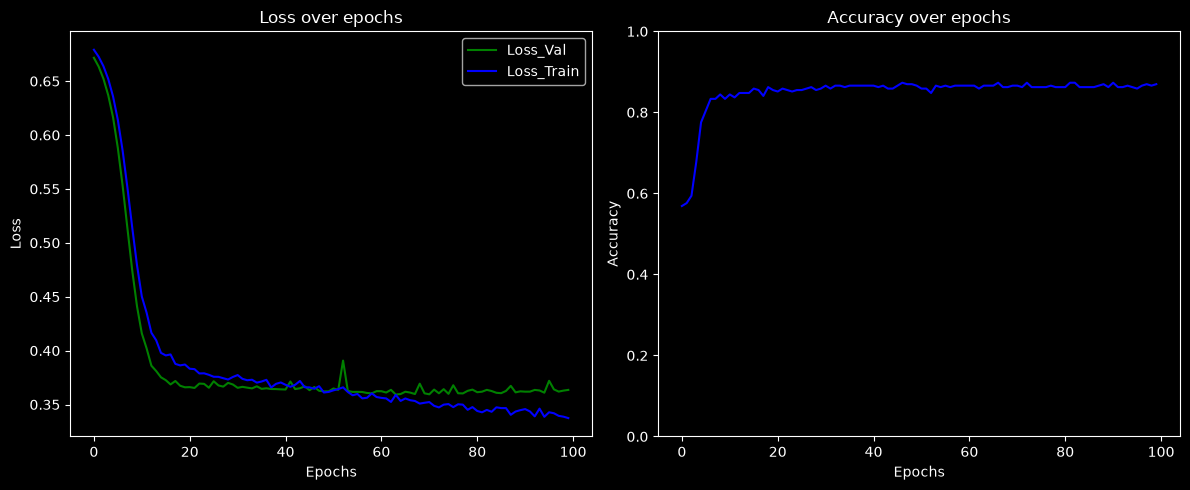

In [43]:
# Melakukan plot kualitas model (loss_train, loss_val dan acc_val) vs training epochs
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
loss = [r['val_loss'] for r in loss_acc_val_history]
plt.plot(loss, '-', color='green')
plt.plot(loss_train_history, '-', color='blue')
plt.title('Loss over epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(['Loss_Val', 'Loss_Train'])

plt.subplot(1, 2, 2)
accuracies = [result['val_acc'] for result in loss_acc_val_history]
plt.plot(accuracies, '-', color='blue')
plt.title('Accuracy over epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.ylim(0,1)

plt.tight_layout()
plt.show()

In [44]:
# Menampilkan semua parameter yang dipelajari dalam arsitektur ANN
for name, param in model.named_parameters():
    print(name)
    print(param.data)

layers.0.weight
tensor([[-0.0589, -0.0828,  0.0038,  0.0476,  0.0087,  0.2452, -0.3136, -0.0687,
          0.0580,  0.3019,  0.2280],
        [-0.0913, -0.0995, -0.1707,  0.0563,  0.1293, -0.1040,  0.0839, -0.2548,
          0.2493,  0.1692, -0.2418],
        [ 0.3479, -0.3707,  0.2795,  0.2683,  0.4981,  0.4789, -0.3022, -0.0323,
          0.5319,  0.1619, -0.1878],
        [-0.2325,  0.4519, -0.4525,  0.3893, -0.4322,  0.0028, -0.1379,  0.2354,
          0.0413, -0.1705, -1.2712],
        [ 0.2227, -0.1735,  0.2102,  0.2299, -0.2172,  0.1027, -0.2242,  0.1028,
         -0.0341, -0.1532,  0.1803],
        [ 0.1867,  0.1820,  0.5696, -0.0398,  0.3794, -0.1764,  0.4884, -0.0542,
          0.0888,  0.6285,  0.6390],
        [-0.0901,  0.0495,  0.1383,  0.2720,  0.2102,  0.1203,  0.0076,  0.0281,
         -0.2181,  0.0089, -0.0040],
        [-0.2098,  0.1487,  0.0743,  0.4895, -0.0145, -0.1464,  0.0958,  0.0231,
         -0.4037, -0.2615, -0.4023],
        [ 0.1932,  0.0334,  0.0749,  0.3

## Testing Process

In [45]:
model.eval()
with torch.inference_mode():
    threshold = 0.5
    X_test_torch = torch.tensor(X_test.values, dtype=torch.float32, device=device)
    y_test_predict = model(X_test_torch)
    y_predict = (y_test_predict.detach().cpu().numpy() >= threshold).astype(int) # Dimensi [N,1]
   
    print(classification_report(y_test, y_predict.reshape(-1)))

              precision    recall  f1-score   support

           0       0.89      0.80      0.84       119
           1       0.86      0.92      0.89       157

    accuracy                           0.87       276
   macro avg       0.87      0.86      0.87       276
weighted avg       0.87      0.87      0.87       276

